# VolatilityQuant — Feature 1A: Single-Ticker Model Development

Historical volatility, GARCH, XGBoost, backtesting and validation. 

**Caution:** Early experiments and later validation use different evaluation designs; do not treat them as a single independent final test.

### Download stock prices

In [1]:
!pip install -q yfinance

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select a stock
ticker = "NVDA"

# Download historical market data
data = yf.download(
    ticker,
    period="5y",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No data returned. Check the ticker.")

# Handle yfinance's column format
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

prices = data["Close"].dropna()

print("Stock:", ticker)
print("Trading days:", len(prices))

display(data.head())



Stock: NVDA
Trading days: 1254


Price,Close,High,Low,Open,Volume
Date,,,,,
2021-11-08,30.668911,30.963612,29.775843,30.016783,503101000
2021-11-09,30.522554,32.168307,29.832595,32.140430,646746000
2021-11-10,29.329813,30.714714,28.651800,29.227266,636206000
2021-11-11,30.256729,30.455853,29.646418,30.334388,332172000
2021-11-12,30.256729,30.545458,29.500062,29.878396,413054000


### Historical volatility

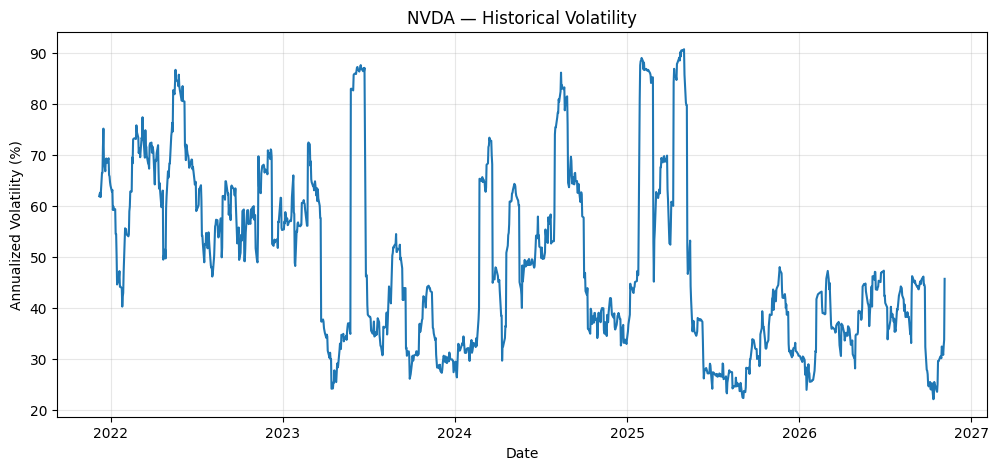

In [2]:

# Calculate daily logarithmic returns
returns = np.log(prices / prices.shift(1)).dropna()

# Calculate rolling 20-day annualized volatility
volatility = returns.rolling(20).std() * np.sqrt(252)

# Plot historical volatility
plt.figure(figsize=(12, 5))
plt.plot(volatility.index, volatility * 100)

plt.title(f"{ticker} — Historical Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.grid(alpha=0.3)
plt.show()


### Install GARCH

In [3]:
!pip install -q arch

### Fit GARCH

In [4]:

from arch import arch_model
import numpy as np

# Use the returns we calculated earlier
# Multiply by 100 so returns are in percentage units
returns_pct = returns * 100

# Create GARCH(1,1) model
model = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

# Estimate model parameters using historical data
results = model.fit(disp="off")

# Display estimated parameters
print(results.summary())


                        Constant Mean - GARCH Model Results                         
Dep. Variable:                        Close   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3159.70
Distribution:      Standardized Student's t   AIC:                           6329.39
Method:                  Maximum Likelihood   BIC:                           6355.06
                                              No. Observations:                 1253
Date:                      Fri, Nov 06 2026   Df Residuals:                     1252
Time:                              11:55:24   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### Forecast five days

In [5]:

# Forecast variance for the next five trading days
forecast = results.forecast(horizon=5)

# Extract daily conditional variance forecasts
daily_variances = forecast.variance.iloc[-1].to_numpy()

# Convert from percentage-squared units to annualized volatility
annualized_vol = (
    np.sqrt(daily_variances.mean() * 252)
)

print("Stock:", ticker)
print(f"5-day GARCH volatility forecast: {annualized_vol:.2f}%")


Stock: NVDA
5-day GARCH volatility forecast: 51.83%


### Compare forecasts

In [6]:

historical_vol = volatility.dropna().iloc[-1] * 100

print("VOLATILITY COMPARISON")
print("---------------------")

print(f"20-day historical volatility: {historical_vol:.2f}%")
print(f"5-day GARCH forecast:        {annualized_vol:.2f}%")

difference = annualized_vol - historical_vol

print(f"Difference:                 {difference:+.2f} percentage points")


VOLATILITY COMPARISON
---------------------
20-day historical volatility: 45.73%
5-day GARCH forecast:        51.83%
Difference:                 +6.09 percentage points


### Plot forecast

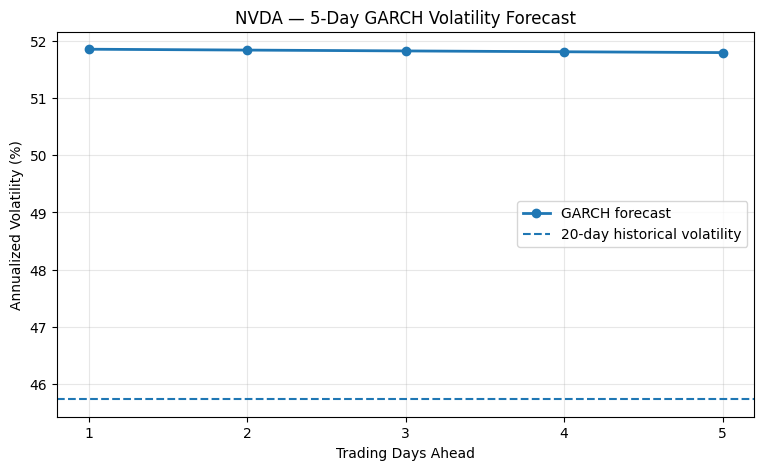

In [7]:

import matplotlib.pyplot as plt
import numpy as np

# GARCH forecast variance for each future trading day
daily_var = forecast.variance.iloc[-1].to_numpy()

# Convert each day's forecast to annualized volatility (%)
daily_vol_forecast = np.sqrt(daily_var * 252)

days = np.arange(1, 6)

plt.figure(figsize=(9, 5))
plt.plot(
    days,
    daily_vol_forecast,
    marker="o",
    linewidth=2,
    label="GARCH forecast"
)

plt.axhline(
    historical_vol,
    linestyle="--",
    label="20-day historical volatility"
)

plt.title(f"{ticker} — 5-Day GARCH Volatility Forecast")
plt.xlabel("Trading Days Ahead")
plt.ylabel("Annualized Volatility (%)")
plt.xticks(days)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Rolling GARCH backtest

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

# Reuse returns from your earlier notebook
returns_pct = (returns.dropna() * 100).copy()

horizon = 5
train_size = int(len(returns_pct) * 0.75)

# Evaluate every 5 trading days to avoid overlapping
# five-day forecast windows
forecast_positions = range(
    train_size,
    len(returns_pct) - horizon + 1,
    horizon
)

records = []

for end in forecast_positions:

    # Only data known at the forecast date
    train = returns_pct.iloc[:end]

    # Fit GARCH(1,1)
    model = arch_model(
        train,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="t"
    )

    fit = model.fit(disp="off", show_warning=False)

    # Predict daily conditional variances
    forecast = fit.forecast(horizon=horizon)
    predicted_var = forecast.variance.iloc[-1].mean()

    # Baseline: past 20-day sample variance
    baseline_var = train.iloc[-20:].var(ddof=1)

    # Actual future realized variance
    future = returns_pct.iloc[end:end + horizon]
    realized_var = np.mean(future.to_numpy() ** 2)

    # Store results in squared percentage-return units
    records.append({
        "Date": train.index[-1],
        "GARCH_Var": predicted_var,
        "Baseline_Var": baseline_var,
        "Realized_Var": realized_var
    })

backtest = pd.DataFrame(records).set_index("Date")

# Convert average daily variance to annualized volatility (%)
for name in ["GARCH", "Baseline", "Realized"]:
    backtest[f"{name}_Vol"] = np.sqrt(
        backtest[f"{name}_Var"] * 252
    )

print("Forecasts evaluated:", len(backtest))
display(backtest.head())


Forecasts evaluated: 62


,GARCH_Var,Baseline_Var,Realized_Var,GARCH_Vol,Baseline_Vol,Realized_Vol
Date,,,,,,
2025-08-07,5.547532,2.985457,0.482172,37.389544,27.428731,11.023036
2025-08-14,4.644241,2.382373,2.851821,34.210360,24.502206,26.807813
2025-08-21,4.812612,2.411701,1.150615,34.824965,24.652560,17.028068
2025-08-28,4.114771,2.234276,4.641041,32.201276,23.728410,34.198571
2025-09-05,5.035447,2.236784,3.414974,35.622080,23.741729,29.335530


### Install ML libraries

In [9]:
!pip install -q xgboost scikit-learn

### Engineer features

In [10]:

import numpy as np
import pandas as pd

# Daily returns in percentage units
r = (returns.dropna() * 100).copy()

features = pd.DataFrame(index=r.index)

# Historical volatility and returns
for window in [5, 10, 20, 60]:
    features[f"var_{window}d"] = r.pow(2).rolling(window).mean()
    features[f"return_{window}d"] = r.rolling(window).sum()

# Additional historical indicators
features["abs_return_1d"] = r.abs()
features["return_1d"] = r
features["negative_return_1d"] = (r < 0).astype(int)

# Future five-day realized variance
horizon = 5

future_variance = pd.concat(
    [r.shift(-i).pow(2) for i in range(1, horizon + 1)],
    axis=1
).mean(axis=1)

# Prevent incomplete future windows
future_variance.iloc[-horizon:] = np.nan

features["target"] = future_variance

dataset = features.dropna()

print("Observations:", len(dataset))
display(dataset.head())


Observations: 1189


,var_5d,return_5d,var_10d,return_10d,var_20d,return_20d,var_60d,return_60d,abs_return_1d,return_1d,negative_return_1d,target
Date,,,,,,,,,,,,
2022-02-03,19.676539,8.739109,14.776212,-0.839959,11.777617,-14.207582,13.397327,-25.163719,5.262444,-5.262444,1,11.349889
2022-02-04,16.946069,6.274463,13.945875,3.963349,11.683996,-14.728362,13.432902,-23.148046,1.537316,1.537316,0,22.240828
2022-02-07,7.817398,0.983485,14.224033,5.639743,11.258663,-9.700722,13.214442,-17.494077,1.667830,1.667830,0,22.032502
2022-02-08,8.205943,1.889649,12.351941,11.752437,11.359271,-8.735643,13.091856,-19.080456,1.525031,1.525031,0,36.998568
2022-02-09,14.637790,5.634167,15.759639,15.931930,13.146445,-4.079655,13.725604,-12.914022,6.166435,6.166435,0,29.394314


### Train initial XGBoost

In [11]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

feature_cols = [
    col for col in dataset.columns if col != "target"
]

# Match the start of the earlier GARCH backtest
test_start = backtest.index.min()

# Remove training rows whose future five-day
# targets overlap the test period
train_end = dataset.index.get_loc(test_start) - horizon

train_data = dataset.iloc[:train_end]
test_data = dataset.loc[dataset.index > test_start]

X_train = train_data[feature_cols]
y_train = train_data["target"]

X_test = test_data[feature_cols]
y_test = test_data["target"]

model_xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

model_xgb.fit(X_train, y_train)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


Training observations: 874
Test observations: 309


### Compare initial forecasts

In [12]:

# Use the exact same dates as the GARCH backtest
comparison = backtest.copy()

X_compare = dataset.loc[
    comparison.index, feature_cols
]

# Predict five-day average daily variance
xgb_var = model_xgb.predict(X_compare)

# Variance must be nonnegative
xgb_var = np.maximum(xgb_var, 1e-8)

comparison["XGBoost_Var"] = xgb_var

# Annualized volatility in percent
comparison["XGBoost_Vol"] = np.sqrt(
    comparison["XGBoost_Var"] * 252
)

# Calculate model errors
actual = comparison["Realized_Vol"]

results = []

for name in ["Baseline", "GARCH", "XGBoost"]:
    predicted = comparison[f"{name}_Vol"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df.round(3))


,Model,MAE,RMSE
1,GARCH,11.192,13.529
0,Baseline,11.459,13.186
2,XGBoost,23.379,32.754


### Model Forecast Accuracy Comparison — NVDA

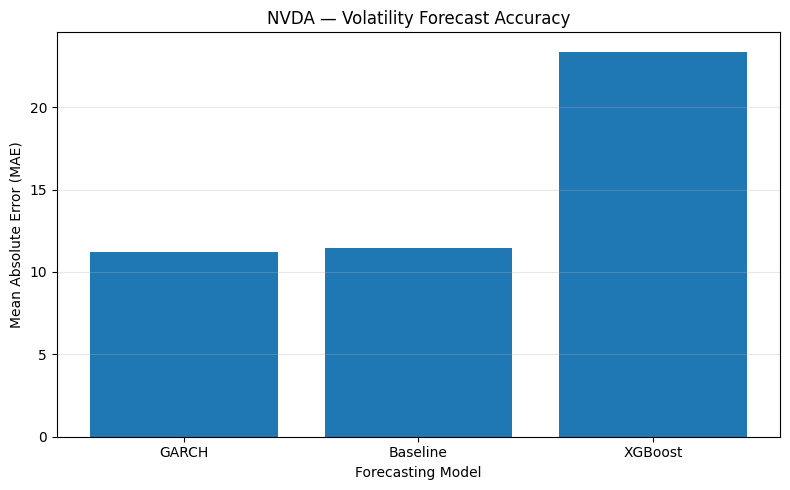

In [13]:
import matplotlib.pyplot as plt

# Create the figure
plt.figure(figsize=(8, 5))

# Create a bar chart comparing the models
plt.bar(results_df["Model"], results_df["MAE"])

# Add titles and labels
plt.title("NVDA — Volatility Forecast Accuracy")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error (MAE)")

# Make the graph easier to read
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save a high-quality image for your slides
plt.savefig("NVDA_MAE_Comparison.png", dpi=300)


### Plot initial comparison

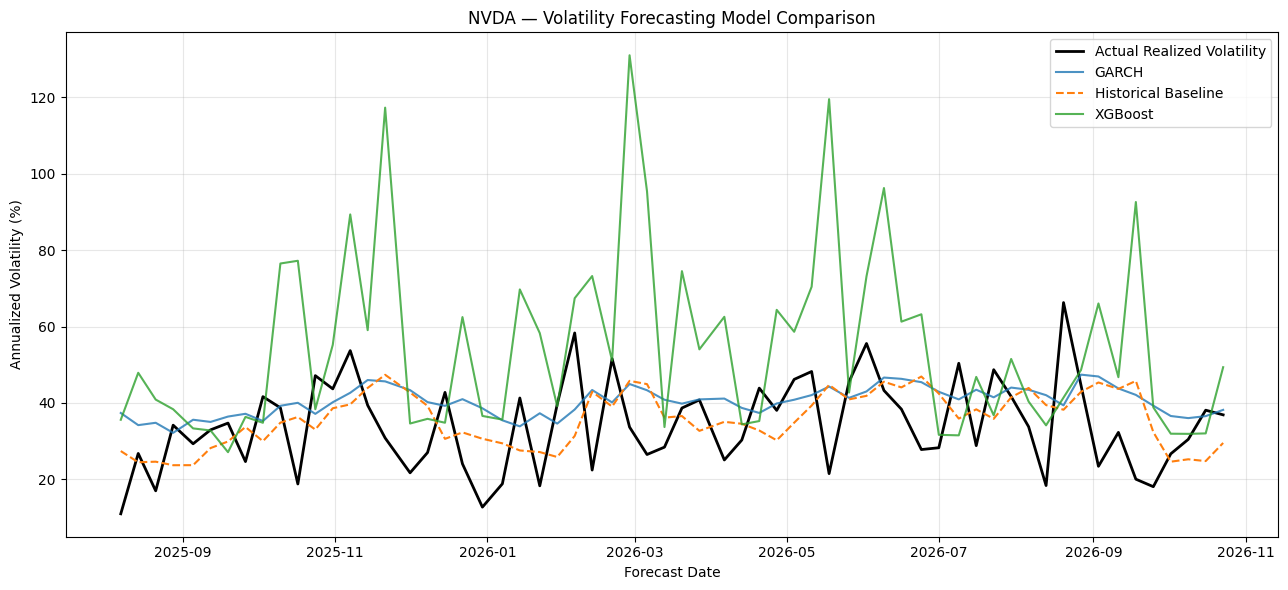

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

plt.plot(
    comparison.index,
    comparison["Realized_Vol"],
    label="Actual Realized Volatility",
    color="black",
    linewidth=2
)

plt.plot(
    comparison.index,
    comparison["GARCH_Vol"],
    label="GARCH",
    alpha=0.8
)

plt.plot(
    comparison.index,
    comparison["Baseline_Vol"],
    label="Historical Baseline",
    linestyle="--"
)

plt.plot(
    comparison.index,
    comparison["XGBoost_Vol"],
    label="XGBoost",
    alpha=0.8
)

plt.title("NVDA — Volatility Forecasting Model Comparison")
plt.xlabel("Forecast Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Chronological validation split

In [15]:

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

# Reuse dataset and feature_cols from earlier
# Dataset includes features and the future 5-day variance target

horizon = 5

# Use the first 70% for training and next 15%
# for validation. Reserve the last 15% untouched.
n = len(dataset)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Purge observations whose future targets
# overlap the next period
train = dataset.iloc[:train_end - horizon]
validation = dataset.iloc[train_end:val_end]

X_train = train[feature_cols]
y_train = train["target"]

X_val = validation[feature_cols]
y_val = validation["target"]

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Reserved test rows:", len(dataset) - val_end)



Training rows: 827
Validation rows: 178
Reserved test rows: 179


### Compare XGBoost configurations

In [16]:

configs = {
    "Very Simple": {
        "n_estimators": 50,
        "max_depth": 2,
        "learning_rate": 0.03
    },
    "Simple": {
        "n_estimators": 100,
        "max_depth": 2,
        "learning_rate": 0.05
    },
    "Moderate": {
        "n_estimators": 150,
        "max_depth": 3,
        "learning_rate": 0.05
    }
}

models = {}
scores = []

for name, params in configs.items():

    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=10,
        min_child_weight=10,
        random_state=42,
        n_jobs=2
    )

    model.fit(X_train, y_train)

    predicted_var = np.maximum(
        model.predict(X_val), 1e-8
    )

    # Convert daily variance to annualized volatility
    predicted_vol = np.sqrt(predicted_var * 252)
    actual_vol = np.sqrt(y_val.to_numpy() * 252)

    mae = mean_absolute_error(actual_vol, predicted_vol)

    models[name] = model

    scores.append({
        "Model": name,
        "Validation MAE": mae
    })

validation_results = pd.DataFrame(scores)
display(validation_results.sort_values("Validation MAE").round(3))


,Model,Validation MAE
1,Simple,21.209
2,Moderate,21.495
0,Very Simple,22.927


### Plot validation

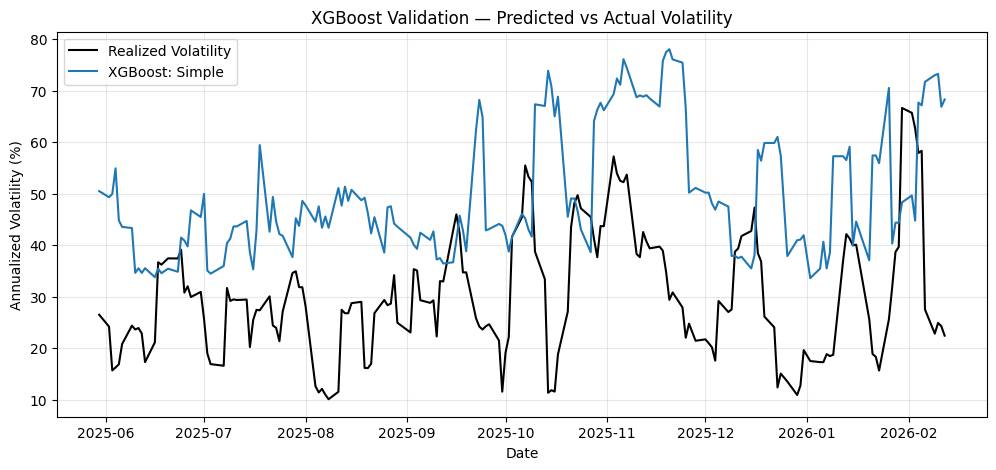

Best configuration: Simple


In [17]:

best_name = validation_results.sort_values(
    "Validation MAE"
).iloc[0]["Model"]

best_model = models[best_name]

best_pred_var = np.maximum(
    best_model.predict(X_val), 1e-8
)

best_pred_vol = np.sqrt(best_pred_var * 252)
actual_vol = np.sqrt(y_val.to_numpy() * 252)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    validation.index,
    actual_vol,
    label="Realized Volatility",
    color="black"
)

plt.plot(
    validation.index,
    best_pred_vol,
    label=f"XGBoost: {best_name}"
)

plt.title("XGBoost Validation — Predicted vs Actual Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best configuration:", best_name)


### Bias diagnostics

In [18]:

import numpy as np
import pandas as pd

# Compare average predicted and realized volatility
diagnostics = pd.DataFrame({
    "Actual": actual_vol,
    "Predicted": best_pred_vol
}, index=validation.index)

diagnostics["Error"] = (
    diagnostics["Predicted"] - diagnostics["Actual"]
)

print("Average actual volatility:",
      round(diagnostics["Actual"].mean(), 2))

print("Average predicted volatility:",
      round(diagnostics["Predicted"].mean(), 2))

print("Mean forecast bias:",
      round(diagnostics["Error"].mean(), 2))

print("Percentage of overpredictions:",
      round((diagnostics["Error"] > 0).mean() * 100, 1),
      "%")


Average actual volatility: 30.1
Average predicted volatility: 49.75
Mean forecast bias: 19.65
Percentage of overpredictions: 88.2 %


### Log-variance experiment

In [19]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Train XGBoost on log future variance
epsilon = 1e-6

log_model = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,
    min_child_weight=10,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=2
)

log_model.fit(
    X_train,
    np.log(y_train + epsilon)
)

# Predict and transform back
log_pred = log_model.predict(X_val)

pred_var = np.maximum(
    np.exp(log_pred) - epsilon, 1e-8
)

pred_vol = np.sqrt(pred_var * 252)

# Compare against actual volatility
actual_vol = np.sqrt(
    y_val.to_numpy() * 252
)

# Historical variance baseline
baseline_var = dataset.loc[
    validation.index, "var_20d"
].to_numpy()

baseline_vol = np.sqrt(
    baseline_var * 252
)

# Original model prediction
original_vol = best_pred_vol

results = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Log-Variance XGBoost",
        "Historical Baseline"
    ],
    "MAE": [
        mean_absolute_error(actual_vol, original_vol),
        mean_absolute_error(actual_vol, pred_vol),
        mean_absolute_error(actual_vol, baseline_vol)
    ],
    "Mean Bias": [
        np.mean(original_vol - actual_vol),
        np.mean(pred_vol - actual_vol),
        np.mean(baseline_vol - actual_vol)
    ]
})

display(results.round(3))


,Model,MAE,Mean Bias
0,Original XGBoost,21.209,19.645
1,Log-Variance XGBoost,11.741,7.042
2,Historical Baseline,11.073,1.454


### Nonoverlapping validation

In [20]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Use nonoverlapping five-day validation windows
val_dates = validation.index[::5]

# Realized future volatility
actual_var = validation.loc[val_dates, "target"].to_numpy()
actual_vol = np.sqrt(actual_var * 252)

# Historical baseline
baseline_var = validation.loc[
    val_dates, "var_20d"
].to_numpy()

baseline_vol = np.sqrt(baseline_var * 252)

# Log-variance XGBoost
xgb_features = validation.loc[val_dates, feature_cols]

log_predictions = log_model.predict(xgb_features)

xgb_var = np.maximum(
    np.exp(log_predictions) - epsilon,
    1e-8
)

xgb_vol = np.sqrt(xgb_var * 252)

# Calculate errors on identical dates
comparison_table = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Log-Variance XGBoost"
    ],
    "MAE": [
        mean_absolute_error(actual_vol, baseline_vol),
        mean_absolute_error(actual_vol, xgb_vol)
    ],
    "Mean Bias": [
        np.mean(baseline_vol - actual_vol),
        np.mean(xgb_vol - actual_vol)
    ]
})

display(comparison_table.round(3))


,Model,MAE,Mean Bias
0,Historical Baseline,11.621,1.594
1,Log-Variance XGBoost,11.775,7.095


### GARCH validation benchmark

In [21]:

from arch import arch_model
import numpy as np
import pandas as pd

garch_predictions = []

# Match the validation dates used previously
for date in val_dates:

    # Historical returns available through this date
    train_returns = returns_pct.loc[:date]

    # Fit GARCH using only past information
    garch_model = arch_model(
        train_returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="t"
    )

    fitted = garch_model.fit(
        disp="off",
        show_warning=False
    )

    # Forecast five-day conditional variance
    forecast_result = fitted.forecast(horizon=5)

    predicted_variance = (
        forecast_result.variance.iloc[-1].mean()
    )

    predicted_volatility = np.sqrt(
        predicted_variance * 252
    )

    garch_predictions.append(predicted_volatility)

garch_vol = np.array(garch_predictions)

# Compare all three models on identical dates
final_validation = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "GARCH(1,1)",
        "Log-Variance XGBoost"
    ],
    "MAE": [
        np.mean(np.abs(baseline_vol - actual_vol)),
        np.mean(np.abs(garch_vol - actual_vol)),
        np.mean(np.abs(xgb_vol - actual_vol))
    ],
    "Mean Bias": [
        np.mean(baseline_vol - actual_vol),
        np.mean(garch_vol - actual_vol),
        np.mean(xgb_vol - actual_vol)
    ]
})

display(final_validation.round(3))


,Model,MAE,Mean Bias
0,Historical Baseline,11.621,1.594
1,"GARCH(1,1)",14.036,9.831
2,Log-Variance XGBoost,11.775,7.095


## GARCH(1,1) Parameter Stability — NVDA

**Research question:** How sensitive are the estimated GARCH parameters to the historical estimation period?

We re-estimate the **same specification used above** (constant mean, GARCH(1,1), Student-t innovations) on rolling windows of **504 trading-day returns**, advancing **63 trading days** each time. We record $\omega$, $\alpha$, $\beta$ and persistence $\alpha+\beta$. A high persistence estimate does **not** itself mean instability; variation *across estimation windows* is what we examine.

This is a **descriptive rolling-estimation diagnostic**, not a formal statistical test of parameter constancy. Overlapping windows create dependence between estimates, and numerical optimization may occasionally fail.

In [22]:
# Run the earlier data-download and historical-return cells first.
# This cell uses the original daily log returns (decimal units), then
# converts them to percentage units exactly once for GARCH estimation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

if "returns" not in globals():
    raise RuntimeError("Run the notebook's earlier 'Historical volatility' cell first to create returns.")

stability_returns_pct = (pd.Series(returns).dropna().astype(float) * 100).copy()
window_days = 504   # ~2 trading years
step_days = 63      # ~3 trading months

if len(stability_returns_pct) < window_days:
    raise ValueError(f"Need {window_days} returns; only {len(stability_returns_pct)} available.")

stability_records = []
for end in range(window_days, len(stability_returns_pct) + 1, step_days):
    sample = stability_returns_pct.iloc[end - window_days:end]
    garch = arch_model(sample, mean="Constant", vol="GARCH", p=1, q=1, dist="t")
    try:
        fitted = garch.fit(disp="off", show_warning=False)
        if fitted.convergence_flag != 0:
            print(f"Skipping {sample.index[-1].date()}: optimization did not converge")
            continue
        p = fitted.params
        alpha, beta = float(p["alpha[1]"]), float(p["beta[1]"])
        stability_records.append({
            "Window end": sample.index[-1],
            "omega": float(p["omega"]),
            "alpha": alpha,
            "beta": beta,
            "alpha + beta": alpha + beta,
        })
    except Exception as exc:
        print(f"Skipping {sample.index[-1]}: {exc}")

stability_df = pd.DataFrame(stability_records)
if stability_df.empty:
    raise RuntimeError("No GARCH fits converged. Inspect the input data and warnings.")
stability_df = stability_df.set_index("Window end")
print(f"Converged windows: {len(stability_df)}")
display(stability_df.round(4))


Converged windows: 12


,omega,alpha,beta,alpha + beta
Window end,,,,
2023-11-09,0.0000,0.0164,0.9816,0.9980
2024-02-12,0.0000,0.0000,0.9967,0.9967
2024-05-13,0.0482,0.0000,0.9927,0.9927
2024-08-13,0.1300,0.0242,0.9635,0.9877
2024-11-11,0.2498,0.0278,0.9438,0.9716
2025-02-13,0.8977,0.0532,0.8497,0.9029
2025-05-15,1.5619,0.0889,0.7728,0.8616
2025-08-15,0.3454,0.0720,0.8931,0.9652
2025-11-13,0.3114,0.0667,0.9034,0.9701


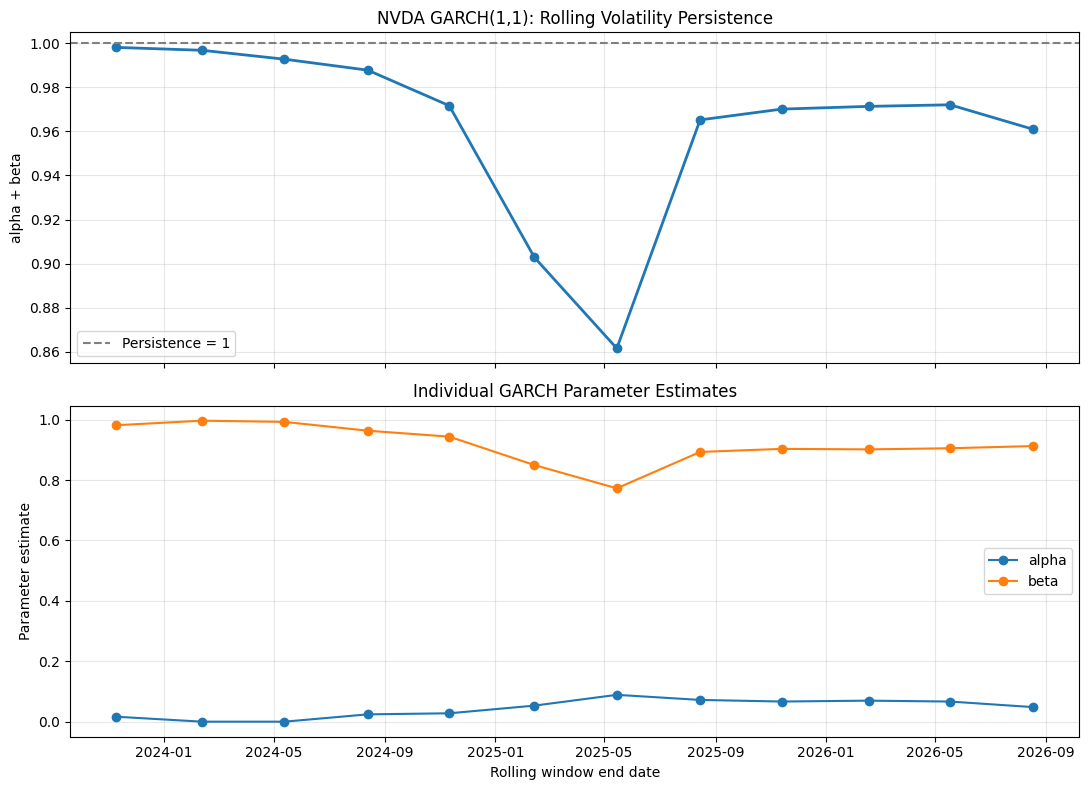

Parameter variation across rolling estimation windows:


,omega,alpha,beta,alpha + beta
mean,0.3621,0.0445,0.9181,0.9625
std,0.4456,0.0299,0.0644,0.0405
min,0.0000,0.0000,0.7728,0.8616
max,1.5619,0.0889,0.9967,0.9980


Persistence range: 0.1364


In [23]:
# Plot persistence and individual parameters across rolling windows
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].plot(stability_df.index, stability_df["alpha + beta"], marker="o", linewidth=2)
axes[0].axhline(1.0, linestyle="--", color="gray", label="Persistence = 1")
axes[0].set_title("NVDA GARCH(1,1): Rolling Volatility Persistence")
axes[0].set_ylabel("alpha + beta")
axes[0].legend()
axes[0].grid(alpha=0.3)
for col in ["alpha", "beta"]:
    axes[1].plot(stability_df.index, stability_df[col], marker="o", label=col)
axes[1].set_title("Individual GARCH Parameter Estimates")
axes[1].set_xlabel("Rolling window end date")
axes[1].set_ylabel("Parameter estimate")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Parameter variation across rolling estimation windows:")
display(stability_df.agg(["mean", "std", "min", "max"]).round(4))
print("Persistence range:", round(stability_df["alpha + beta"].max() - stability_df["alpha + beta"].min(), 4))
